# Question 6.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

import warnings
warnings.filterwarnings("ignore")

## Step 1: Load the Aggregation dataset

data shape: (788, 2)
number of true clusters: 7


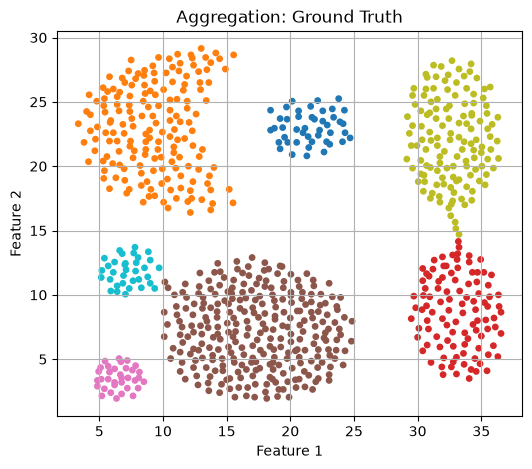

In [9]:
data = np.loadtxt('Aggregation.data.gz')
labels = np.loadtxt('Aggregation.labels.gz')

print("data shape:", data.shape)
print("number of true clusters:", len(np.unique(labels)))

plt.figure(figsize=(6, 5))
plt.scatter(data[:, 0], data[:, 1], c=labels, cmap='tab10', s=15)
plt.title('Aggregation: Ground Truth')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

In [10]:
#Step 2
k_values = [6, 7, 8]

def make_models(k):
    return {
        'k-means': KMeans(n_clusters=k, random_state=42, n_init=10),
        'Hierarchical (average)': AgglomerativeClustering(n_clusters=k, linkage='average'),
        'Spectral (kNN, 10)': SpectralClustering(n_clusters=k, affinity='nearest_neighbors',
                                                 n_neighbors=10, assign_labels='kmeans',
                                                 random_state=42),
    }

preds = {}
for k in k_values:
    for name, model in make_models(k).items():
        preds[(name, k)] = model.fit_predict(data)

## Steps 3–4: ARI and NMI

In [11]:
rows = []
for (name, k), pred in preds.items():
    rows.append({'method': name, 'k': k,
                 'ARI': adjusted_rand_score(labels, pred),
                 'NMI': normalized_mutual_info_score(labels, pred)})

results = pd.DataFrame(rows)
table = results.pivot(index='method', columns='k', values=['ARI', 'NMI']).round(3)
table

ARI                  NMI              
k                           6      7      8      6      7      8
method                                                          
Hierarchical (average)  0.989  1.000  0.972  0.982  1.000  0.978
Spectral (kNN, 10)      0.914  0.992  0.800  0.954  0.988  0.926
k-means                 0.791  0.762  0.676  0.874  0.879  0.850

In [12]:
rows = []
for linkage in ['single', 'complete', 'average', 'ward']:
    for k in k_values:
        pred = AgglomerativeClustering(n_clusters=k, linkage=linkage).fit_predict(data)
        rows.append({'linkage': linkage, 'k': k, 'ARI': adjusted_rand_score(labels, pred)})
pd.DataFrame(rows).pivot(index='linkage', columns='k', values='ARI').round(3)

k,6,7,8
linkage,,,
average,0.989,1.000,0.972
complete,0.757,0.774,0.690
single,0.806,0.804,0.803
ward,0.989,0.813,0.727


## Step 5: Ground truth vs. the three methods (k = 7)

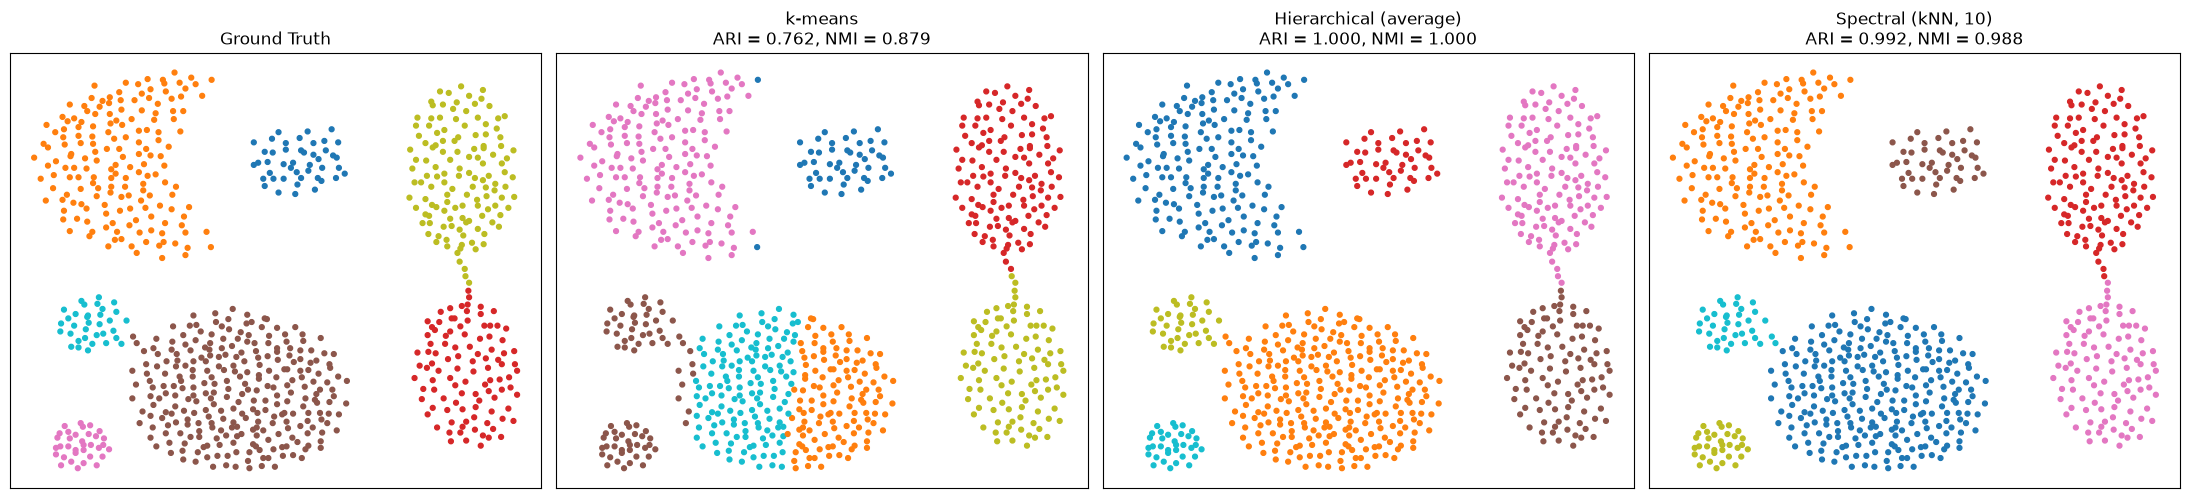

In [13]:
k = 7
panels = [(labels, 'Ground Truth')] + [(preds[(name, k)], name) for name in make_models(k)]

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (lab, title) in zip(axes, panels):
    ax.scatter(data[:, 0], data[:, 1], c=lab, cmap='tab10', s=12)
    if title != 'Ground Truth':
        title += f"\nARI = {adjusted_rand_score(labels, lab):.3f}, NMI = {normalized_mutual_info_score(labels, lab):.3f}"
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect('equal')

plt.tight_layout()
plt.show()

## Step 6: Discussion

**(a) Which method performed best overall, and why?** 

Hierarchical clustering with average linkage performed best. It had the highest ARI and NMI for every k and matched the ground truth exactly at k = 7. The clusters are separated by clear gaps, and average linkage merges groups based on their average distance, so it is not thrown off by a few bridge points and does not force clusters to be round.

**(b) How did the non-convex geometry of the dataset affect the methods?** The non-convex shapes affect k-means the most. k-means assigns each point to the nearest center, so it can only make round, convex clusters. Because of this, it cut the large non-convex blob in half and merged the two small blobs on the lower left. Spectral and hierarchical clustering were barely affected, because they group points by how they connect to nearby points instead of by distance to a center, so they can follow any shape.

**(c) Were the numerical metrics consistent with the visual impressions?** Yes. k-means visibly splits and merges clusters and has the lowest ARI. Spectral looks almost perfect except for the bridge points, and average linkage matches the ground truth exactly.

**(d) What limitations of the methods became visible in this experiment?** All three methods need k in advance. k-means cannot find non-convex clusters. Hierarchical clustering depends a lot on the linkage choice and is slow for large data. Spectral clustering depends on how the similarity graph is built, and points that connect two clusters can be assigned to the wrong one.